# 01 — Exploratory data analysis of UNSW-NB15

Phase 1 of `IMPLEMENTATION_ROADMAP.md`. Every number quoted about the dataset is saved here to
`reports/tables/eda_*.csv` or `reports/figures/eda_*.png`.

**Train** = the 175,341-row partition and **test** = the 82,332-row partition. The official
files are named the other way round; `configs/config.yaml` maps them.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from cnad.config import get_config
from cnad.data.load import CLASSES, load_both

cfg = get_config()
TABLES, FIGURES = cfg["paths"]["tables"], cfg["paths"]["figures"]
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

train, test = load_both(cfg)
splits = {"train": train, "test": test}
NUMERIC = [c for c in train.select_dtypes("number").columns if c != "label"]
TARGETS = ["tcprtt", "synack"]


def save_table(df, name):
    df.to_csv(TABLES / f"eda_{name}.csv")
    return df


def save_fig(fig, name):
    fig.savefig(FIGURES / f"eda_{name}.png", dpi=150, bbox_inches="tight")


def groups(df):
    """All rows, normal rows and attack rows of one split."""
    return {"all": df, "normal": df[df["label"] == 0], "attack": df[df["label"] == 1]}


print({s: df.shape for s, df in splits.items()}, f"{len(NUMERIC)} numeric features")

{'train': (175341, 44), 'test': (82332, 44)} 39 numeric features


## 1. Rows per class, train vs test

In [2]:
counts = pd.DataFrame({s: df["attack_cat"].value_counts() for s, df in splits.items()})
counts = counts.reindex(CLASSES)
counts.index.name = "attack_cat"
for s in splits:
    counts[f"{s}_pct"] = (100 * counts[s] / counts[s].sum()).round(2)
counts.loc["Total"] = [len(train), len(test), 100.0, 100.0]

for s, df in splits.items():
    assert len(df) == cfg["data"]["expected_rows"][s], s
    assert ((df["attack_cat"] == "Normal") == (df["label"] == 0)).all(), s

save_table(counts.astype({"train": int, "test": int}), "class_counts")

,train,test,train_pct,test_pct
attack_cat,,,,
Normal,56000,37000,31.94,44.94
Generic,40000,18871,22.81,22.92
Exploits,33393,11132,19.04,13.52
Fuzzers,18184,6062,10.37,7.36
DoS,12264,4089,6.99,4.97
Reconnaissance,10491,3496,5.98,4.25
Analysis,2000,677,1.14,0.82
Backdoor,1746,583,1.00,0.71
Shellcode,1133,378,0.65,0.46


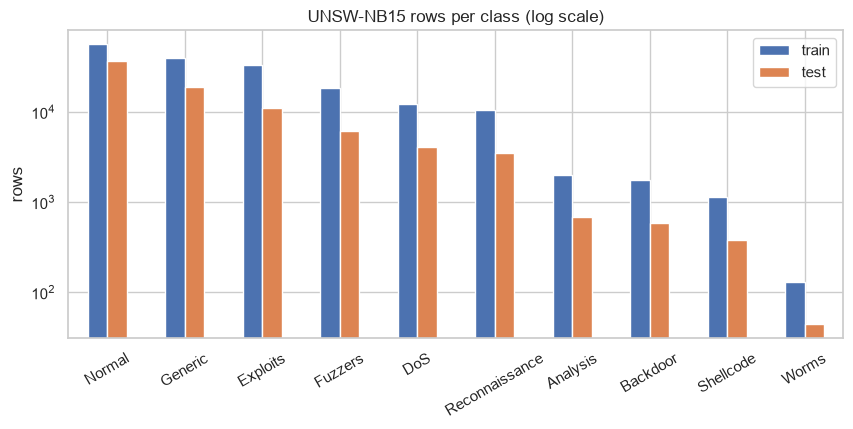

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
counts.drop("Total")[["train", "test"]].plot.bar(ax=ax, logy=True)
ax.set(title="UNSW-NB15 rows per class (log scale)", xlabel="", ylabel="rows")
ax.tick_params(axis="x", rotation=30)
save_fig(fig, "class_counts")

## 2. Missing and infinite values

In [4]:
quality = pd.concat(
    {
        **{f"{s}_missing": df.isna().sum() for s, df in splits.items()},
        **{f"{s}_infinite": np.isinf(df[NUMERIC]).sum() for s, df in splits.items()},
    },
    axis=1,
).fillna(0).astype(int)
quality.index.name = "column"
save_table(quality, "missing_infinite")
print("Columns with any missing/infinite value:", quality[quality.sum(axis=1) > 0].index.tolist())

Columns with any missing/infinite value: []


## 3. Value counts for `proto`, `service`, `state`

In [5]:
cat_summary = {}
for col in ["proto", "service", "state"]:
    vc = pd.DataFrame({s: df[col].value_counts() for s, df in splits.items()})
    vc = vc.fillna(0).astype(int).sort_values("train", ascending=False)
    vc.index.name = col
    save_table(vc, f"values_{col}")
    cat_summary[col] = {
        "distinct_train": int((vc["train"] > 0).sum()),
        "distinct_test": int((vc["test"] > 0).sum()),
        "test_only_values": ", ".join(vc.index[(vc["train"] == 0) & (vc["test"] > 0)]),
        "train_only_values": ", ".join(vc.index[(vc["train"] > 0) & (vc["test"] == 0)]),
        "top10_share_train_pct": round(100 * vc["train"].head(10).sum() / len(train), 2),
    }
    print(f"--- {col}\n", vc.head(10).to_string(), "\n")
cat_summary = save_table(pd.DataFrame(cat_summary).T, "categorical_summary")
cat_summary

--- proto
         train   test
proto               
tcp     79946  43095
udp     63283  29418
unas    12084   3515
arp      2859    987
ospf     2595    676
sctp     1150    324
any       300     96
gre       225     88
swipe     201     52
mobile    201     52 

--- service
           train   test
service               
-         94168  47153
dns       47294  21367
http      18724   8287
smtp       5058   1851
ftp-data   3995   1396
ftp        3428   1552
ssh        1302    204
pop3       1105    423
dhcp         94     26
snmp         80     29 

--- state
        train   test
state              
INT    82275  34163
FIN    77825  39339
CON    13152   6982
REQ     1991   1842
RST       83      1
ECO       12      0
PAR        1      0
URN        1      0
no         1      0
CLO        0      1 



,distinct_train,distinct_test,test_only_values,train_only_values,top10_share_train_pct
proto,133,131,,"icmp, rtp",92.87
service,13,13,,,99.95
state,9,7,"CLO, ACC","ECO, PAR, URN, no",100.0


## 4. TCP rows and rows with a measured handshake

The DNN (split C) uses **normal TCP rows with `tcprtt > 0` and `synack > 0`**. The `normal`
rows of this table give the size of that set before the validation split.

In [6]:
def coverage(df):
    tcp = df["proto"] == "tcp"
    handshake = tcp & (df["tcprtt"] > 0) & (df["synack"] > 0)
    return {
        "rows": len(df),
        "tcp_rows": int(tcp.sum()),
        "tcp_pct_of_rows": round(100 * tcp.mean(), 2),
        "tcp_with_rtt_and_synack": int(handshake.sum()),
        "pct_of_tcp": round(100 * handshake.sum() / max(tcp.sum(), 1), 2),
        "pct_of_rows": round(100 * handshake.mean(), 2),
        "non_tcp_with_tcprtt_gt_0": int((~tcp & (df["tcprtt"] > 0)).sum()),
    }


tcp_cov = pd.DataFrame(
    {(s, g): coverage(part) for s, df in splits.items() for g, part in groups(df).items()}
).T
tcp_cov.index.names = ["split", "group"]
save_table(tcp_cov, "tcp_handshake_coverage")

rows  tcp_rows  tcp_pct_of_rows  tcp_with_rtt_and_synack  pct_of_tcp  pct_of_rows  non_tcp_with_tcprtt_gt_0
split group                                                                                                                  
train all     175341.0   79946.0            45.59                  79041.0       98.87        45.08                       0.0
      normal   56000.0   39121.0            69.86                  38244.0       97.76        68.29                       0.0
      attack  119341.0   40825.0            34.21                  40797.0       99.93        34.19                       0.0
test  all      82332.0   43095.0            52.34                  41205.0       95.61        50.05                       0.0
      normal   37000.0   27848.0            75.26                  26082.0       93.66        70.49                       0.0
      attack   45332.0   15247.0            33.63                  15123.0       99.19        33.36                       0.0

## 5. Distribution of `tcprtt` (latency) and `synack` (response time), normal vs attack

Rows: TCP with both values > 0, training split. Units are seconds.

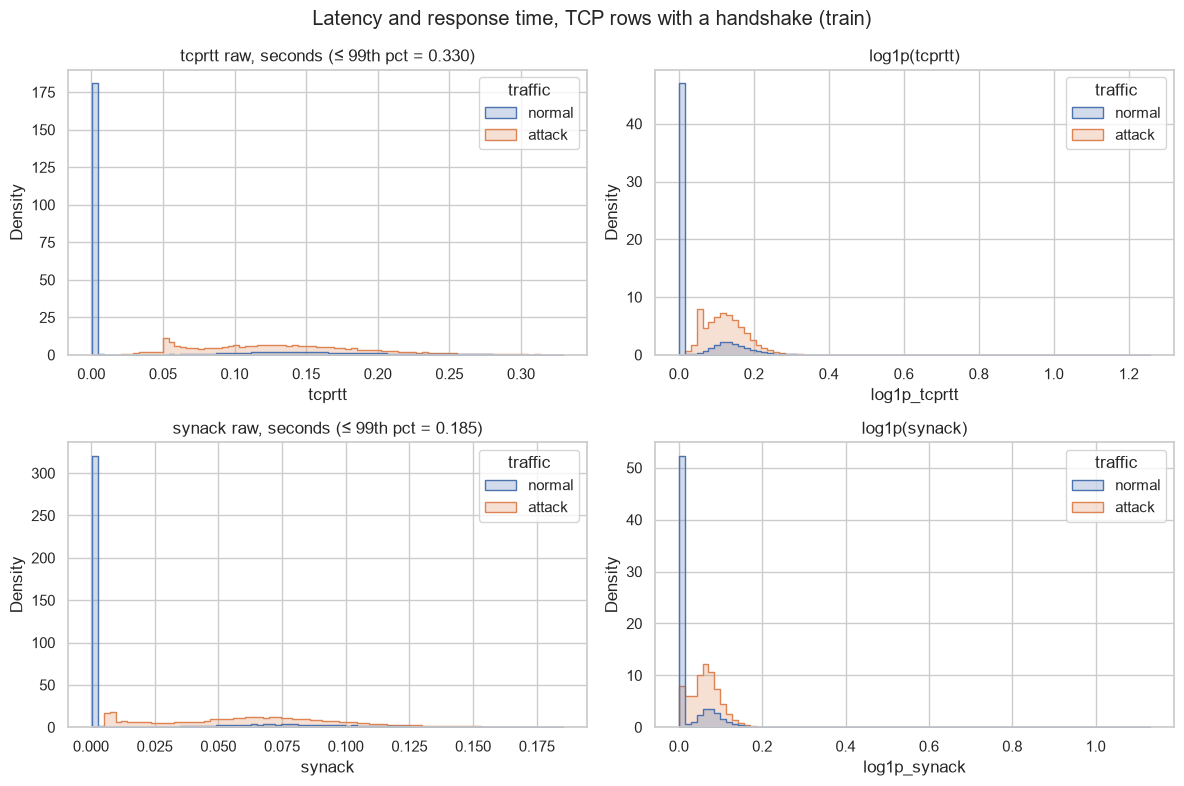

In [7]:
def handshake_rows(df):
    return df[(df["proto"] == "tcp") & (df["tcprtt"] > 0) & (df["synack"] > 0)].assign(
        traffic=lambda d: np.where(d["label"] == 0, "normal", "attack")
    )


hs_train = handshake_rows(train)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, target in enumerate(TARGETS):
    cap = hs_train[target].quantile(0.99)
    sns.histplot(
        data=hs_train[hs_train[target] <= cap], x=target, hue="traffic", bins=80,
        stat="density", common_norm=False, element="step", ax=axes[row, 0],
    )
    axes[row, 0].set_title(f"{target} raw, seconds (≤ 99th pct = {cap:.3f})")
    sns.histplot(
        data=hs_train.assign(**{f"log1p_{target}": np.log1p(hs_train[target])}),
        x=f"log1p_{target}", hue="traffic", bins=80, stat="density", common_norm=False,
        element="step", log_scale=(False, False), ax=axes[row, 1],
    )
    axes[row, 1].set_title(f"log1p({target})")
fig.suptitle("Latency and response time, TCP rows with a handshake (train)")
fig.tight_layout()
save_fig(fig, "latency_distributions")

In [8]:
def describe(s):
    q = s.quantile([0.5, 0.95, 0.99])
    return {"count": len(s), "mean": s.mean(), "median": q[0.5], "p95": q[0.95],
            "p99": q[0.99], "max": s.max(), "skew": s.skew()}


lat_stats = pd.DataFrame(
    {
        (split, traffic, target): describe(part[target])
        for split, df in splits.items()
        for traffic, part in handshake_rows(df).groupby("traffic")
        for target in TARGETS
    }
).T.round(5)
lat_stats.index.names = ["split", "traffic", "target"]
save_table(lat_stats, "latency_stats")

count     mean   median      p95      p99      max      skew
split traffic target                                                                
train attack  tcprtt  40797.0  0.13406  0.12780  0.24748  0.31276  1.49070   1.37228
              synack  40797.0  0.06656  0.06520  0.13488  0.17945  0.51313   0.95867
      normal  tcprtt  38244.0  0.04678  0.00070  0.21217  0.37816  2.51889   5.93805
              synack  38244.0  0.02537  0.00056  0.11572  0.20062  2.10035   8.09005
test  attack  tcprtt  15123.0  0.12089  0.11295  0.23332  0.29468  0.74074   1.06278
              synack  15123.0  0.05893  0.05692  0.12954  0.17041  0.59514   1.19401
      normal  tcprtt  26082.0  0.10644  0.09486  0.28613  0.68916  3.82146   7.47941
              synack  26082.0  0.05818  0.04519  0.16084  0.37201  3.22679  10.59632

In [9]:
by_class = pd.concat(
    {
        s: handshake_rows(df).groupby("attack_cat")[TARGETS].agg(["count", "median"])
        for s, df in splits.items()
    },
    axis=1,
).reindex(CLASSES).round(5)
save_table(by_class, "latency_by_class")

train                            test                         
               tcprtt          synack          tcprtt          synack         
                count   median  count   median  count   median  count   median
attack_cat                                                                    
Normal          38244  0.00070  38244  0.00056  26082  0.09486  26082  0.04519
Generic           485  0.12179    485  0.06200    517  0.10606    517  0.05006
Exploits        19665  0.11684  19665  0.05818   7691  0.09984   7691  0.04920
Fuzzers         11759  0.14913  11759  0.07794   3679  0.14152   3679  0.07480
DoS              2281  0.10979   2281  0.05321   1045  0.09538   1045  0.04660
Reconnaissance   5100  0.11630   5100  0.05843   1851  0.10355   1851  0.05088
Analysis          564  0.14966    564  0.07863     58  0.15392     58  0.07925
Backdoor          271  0.12409    271  0.05998     51  0.09702     51  0.04843
Shellcode         557  0.11712    557  0.05862    193  0.10453    193  0.05257
Worms             115  0.13603    115  0.06957     38  0.12111     38  0.06814

### 5b. Two latency regimes in normal traffic, set by the TTL pair

Normal handshake rows split into a fast regime (sub-10 ms, `sttl/dttl = 31/29`) and a slow
regime (~100 ms, `254/252` and `62/252`). The mix differs between train and test, which is
why the normal median `tcprtt` differs so much. `sttl`/`dttl` stay in the DNN inputs, so the
model can tell the regimes apart.

In [10]:
def regimes(df):
    h = handshake_rows(df)
    h = h[h["traffic"] == "normal"]
    g = h.groupby(["sttl", "dttl"])["tcprtt"]
    out = pd.DataFrame({
        "rows": g.size(),
        "pct_of_normal_handshake_rows": (100 * g.size() / len(h)).round(2),
        "median_tcprtt_s": g.median().round(5),
        "pct_tcprtt_below_10ms": (100 * g.apply(lambda s: (s < 0.01).mean())).round(2),
    })
    return out.sort_values("rows", ascending=False).head(5)


latency_regimes = save_table(
    pd.concat({s: regimes(df) for s, df in splits.items()}, names=["split"]), "latency_regimes"
)
latency_regimes

rows  pct_of_normal_handshake_rows  median_tcprtt_s  pct_tcprtt_below_10ms
split sttl dttl                                                                             
train 31   29    28459                         74.41          0.00067                  99.16
      254  252    7551                         19.74          0.15038                   0.00
      62   252    2163                          5.66          0.16209                   0.00
      254  60       71                          0.19          0.10262                   0.00
test  31   29    12049                         46.20          0.00068                  99.90
      254  252    9862                         37.81          0.15554                   0.00
      62   252    4127                         15.82          0.17670                   0.00
      31   30       27                          0.10          0.00062                 100.00
      32   29       10                          0.04          0.00064                 100.00

## 6. Leakage check: `tcprtt = synack + ackdat`

If this holds, `synack` and `ackdat` together give away `tcprtt`, so all three are excluded
from the DNN inputs.

In [11]:
leak_rows = {}
for s, df in splits.items():
    total = df["synack"] + df["ackdat"]
    diff = (df["tcprtt"] - total).abs()
    leak_rows[s] = {
        "rows": len(df),
        "max_abs_diff_s": diff.max(),
        "mean_abs_diff_s": diff.mean(),
        "pct_rows_within_1e-5_s": round(100 * (diff <= 1e-5).mean(), 4),
        "pearson_r": np.corrcoef(df["tcprtt"], total)[0, 1],
    }
leakage = save_table(pd.DataFrame(leak_rows).T, "leakage_check")
leakage

,rows,max_abs_diff_s,mean_abs_diff_s,pct_rows_within_1e-5_s,pearson_r
train,175341.0,4.440892e-16,1.498998e-18,100.0,1.0
test,82332.0,4.440892e-16,2.038967e-18,100.0,1.0


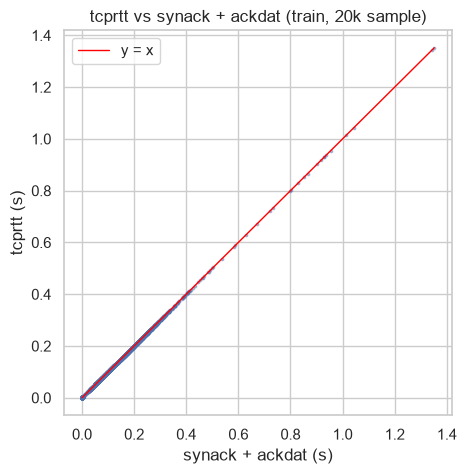

In [12]:
sample = train.sample(20_000, random_state=cfg["seed"])
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(sample["synack"] + sample["ackdat"], sample["tcprtt"], s=3, alpha=0.4)
lim = sample["tcprtt"].max()
ax.plot([0, lim], [0, lim], color="red", linewidth=1, label="y = x")
ax.set(xlabel="synack + ackdat (s)", ylabel="tcprtt (s)",
       title="tcprtt vs synack + ackdat (train, 20k sample)")
ax.legend()
save_fig(fig, "leakage_check")

## 7. Packet loss: share of rows with zero `sloss` / `dloss`

In [13]:
loss = pd.DataFrame(
    {
        (s, g): {
            "rows": len(part),
            "sloss_zero_pct": round(100 * (part["sloss"] == 0).mean(), 2),
            "dloss_zero_pct": round(100 * (part["dloss"] == 0).mean(), 2),
            "both_zero_pct": round(100 * ((part["sloss"] == 0) & (part["dloss"] == 0)).mean(), 2),
        }
        for s, df in splits.items()
        for g, part in groups(df).items()
    }
).T
loss.index.names = ["split", "group"]
save_table(loss, "loss_zero_share")

rows  sloss_zero_pct  dloss_zero_pct  both_zero_pct
split group                                                          
train all     175341.0           54.44           55.11          54.42
      normal   56000.0           30.17           31.91          30.16
      attack  119341.0           65.82           66.00          65.80
test  all      82332.0           47.76           50.05          47.70
      normal   37000.0           24.86           29.64          24.79
      attack   45332.0           66.44           66.70          66.39

## 8. Correlation of the numeric features (train)

Constant columns: []
16 pairs with |r| >= 0.9


,,r
feature_a,feature_b,
is_ftp_login,ct_ftp_cmd,1.000
dbytes,dloss,0.997
sbytes,sloss,0.996
swin,dwin,0.990
ct_srv_src,ct_srv_dst,0.980
dpkts,dloss,0.979
ct_dst_src_ltm,ct_srv_dst,0.972
dpkts,dbytes,0.972
spkts,sloss,0.971


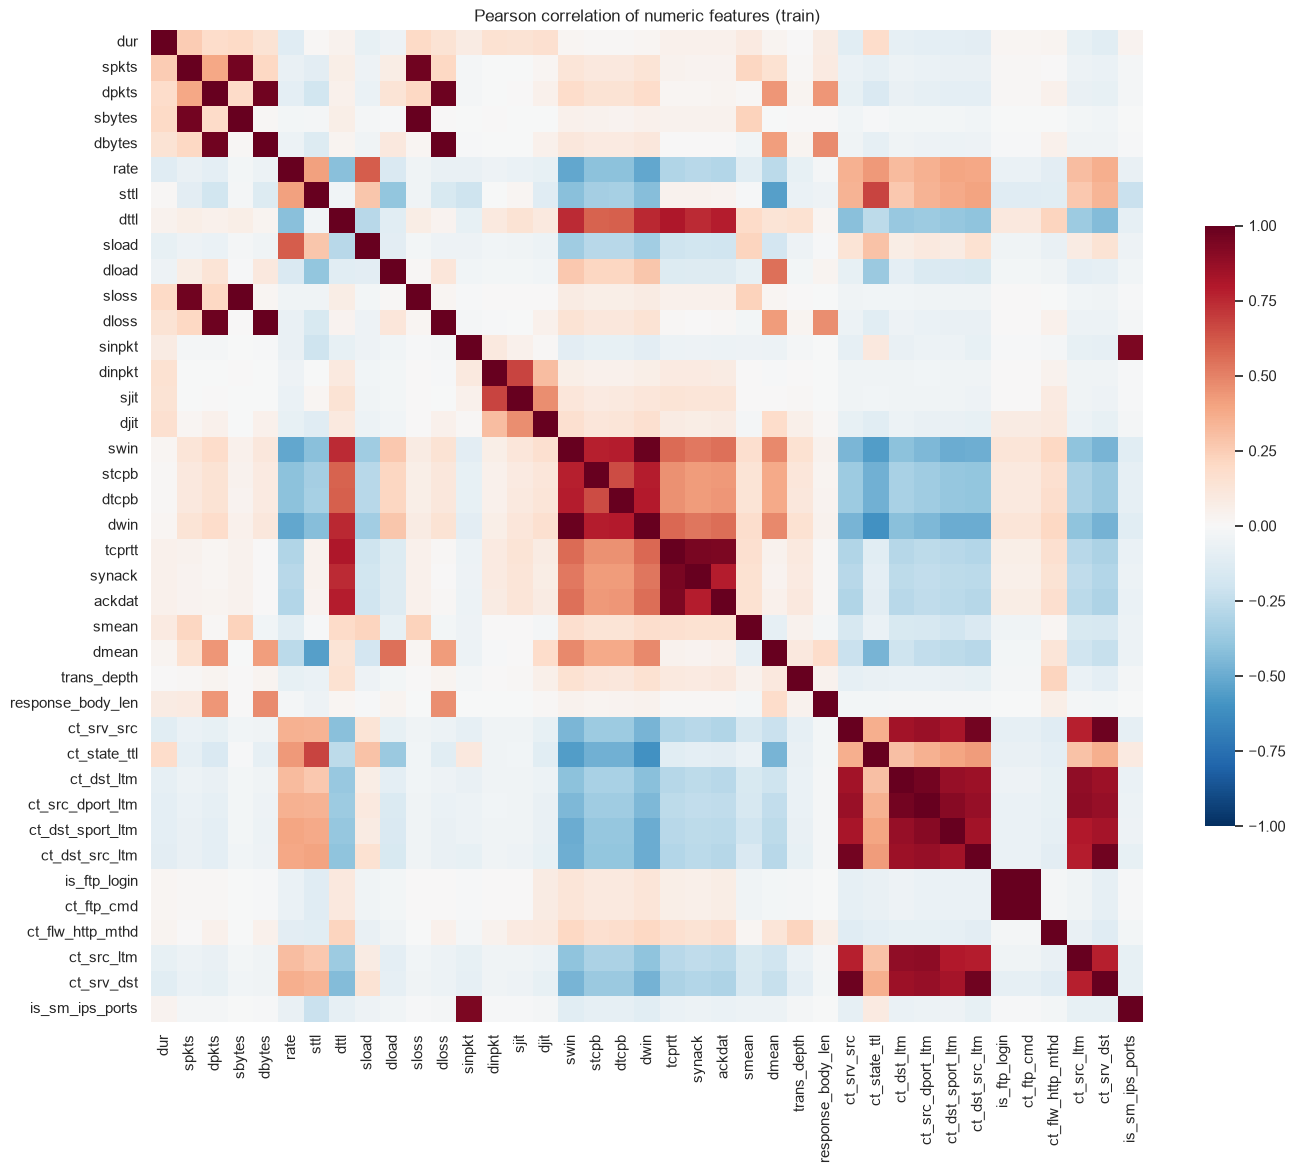

In [14]:
corr = train[NUMERIC].corr()
fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={"shrink": 0.6})
ax.set_title("Pearson correlation of numeric features (train)")
save_fig(fig, "correlation_heatmap")

constant = [c for c in NUMERIC if train[c].nunique() <= 1]
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
high_pairs = upper[upper.abs() >= 0.9].sort_values(key=abs, ascending=False)
high_pairs.index.names = ["feature_a", "feature_b"]
save_table(high_pairs.rename("pearson_r").round(4).to_frame(), "high_correlation_pairs")
print("Constant columns:", constant)
print(f"{len(high_pairs)} pairs with |r| >= 0.9")
high_pairs.round(3).to_frame("r")

## 9. Key numbers (one table for the data-facts note and Review 2 slides)

In [15]:
normal_hs = tcp_cov.loc[[("train", "normal"), ("test", "normal")], "tcp_with_rtt_and_synack"]
key = {
    "train_rows": len(train),
    "test_rows": len(test),
    "train_normal_pct": counts.loc["Normal", "train_pct"],
    "test_normal_pct": counts.loc["Normal", "test_pct"],
    "numeric_features": len(NUMERIC),
    "categorical_features": 3,
    "missing_values_total": int(quality.filter(like="missing").to_numpy().sum()),
    "infinite_values_total": int(quality.filter(like="infinite").to_numpy().sum()),
    "proto_distinct_train": cat_summary.loc["proto", "distinct_train"],
    "service_distinct_train": cat_summary.loc["service", "distinct_train"],
    "state_distinct_train": cat_summary.loc["state", "distinct_train"],
    "train_tcp_pct": tcp_cov.loc[("train", "all"), "tcp_pct_of_rows"],
    "regression_rows_train_normal_tcp_handshake": int(normal_hs.iloc[0]),
    "regression_rows_test_normal_tcp_handshake": int(normal_hs.iloc[1]),
    "train_normal_median_tcprtt_s": lat_stats.loc[("train", "normal", "tcprtt"), "median"],
    "test_normal_median_tcprtt_s": lat_stats.loc[("test", "normal", "tcprtt"), "median"],
    "leakage_pct_rows_exact_train": leakage.loc["train", "pct_rows_within_1e-5_s"],
    "train_both_loss_zero_pct": loss.loc[("train", "all"), "both_zero_pct"],
    "train_normal_both_loss_zero_pct": loss.loc[("train", "normal"), "both_zero_pct"],
    "constant_numeric_columns": ", ".join(constant) or "none",
    "feature_pairs_abs_r_ge_0.9": len(high_pairs),
}
key_numbers = save_table(pd.Series(key, name="value").to_frame(), "key_numbers")
key_numbers

,value
train_rows,175341
test_rows,82332
train_normal_pct,31.94
test_normal_pct,44.94
numeric_features,39
categorical_features,3
missing_values_total,0
infinite_values_total,0
proto_distinct_train,133
service_distinct_train,13
